Preprocessing
Feature Engineering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("loan_applications.csv",na_values=['?',-999])

In [6]:
df.head(20)

,applicant_id,age,gender,city,education,employment_type,years_experience,annual_income,co_applicant_income,credit_score,existing_loans,loan_amount,loan_approved
0,APP1001,24.0,Male,Hyderabad,Post Graduate,Self-Employed,0.0,308000.0,NaN,696.0,0,830000,1
1,APP1002,51.0,Male,Hyderabad,Post Graduate,Self-Employed,27.0,1445000.0,550000.0,751.0,0,3060000,0
2,APP1003,47.0,Male,Chandigarh,Post Graduate,Salaried,22.0,493000.0,374000.0,801.0,0,530000,1
3,APP1004,38.0,Male,Bengaluru,Graduate,Salaried,13.0,487000.0,NaN,724.0,0,910000,0
4,APP1005,38.0,Female,Pune,NaN,Salaried,14.0,436000.0,NaN,828.0,0,1040000,1
5,APP1006,55.0,Female,Bengaluru,Post Graduate,Salaried,32.0,NaN,NaN,758.0,0,3340000,0
6,APP1007,24.0,Male,Hyderabad,Graduate,Salaried,NaN,300000.0,NaN,685.0,2,270000,1
7,APP1008,48.0,Female,Bengaluru,Post Graduate,Salaried,25.0,809000.0,167000.0,754.0,1,660000,1
8,APP1009,29.0,Male,Mumbai,Graduate,Business,5.0,408000.0,NaN,811.0,3,630000,1
9,APP1010,24.0,Male,Bengaluru,High School,Salaried,0.0,224000.0,239000.0,830.0,0,180000,1


In [8]:
df.isnull().sum()

applicant_id             0
age                     44
gender                  26
city                    33
education               61
employment_type         57
years_experience       106
annual_income          122
co_applicant_income    669
credit_score            73
existing_loans           0
loan_amount              0
loan_approved            0
dtype: int64

In [9]:
df.shape

(1000, 13)

1. - MCAR : Missing compeletly at random
2. - MAR : Missing at random
3. - MNAR : Missing not at random

In [ ]:
exp_missing = df['years_experience'].isnull()

print(df.loc[exp_missing,"age"].mean().round(2))
print(df.loc[~exp_missing,"age"].mean().round(2))
# MAR

30.27
41.96


Detection

In [15]:
missing = pd.DataFrame(
    {
        "missing_count":df.isnull().sum(),
        "missing_pct":df.isnull().mean() * 100
    }
    )

In [16]:
missing

,missing_count,missing_pct
applicant_id,0,0.0
age,44,4.4
gender,26,2.6
city,33,3.3
education,61,6.1
employment_type,57,5.7
years_experience,106,10.6
annual_income,122,12.2
co_applicant_income,669,66.9
credit_score,73,7.3


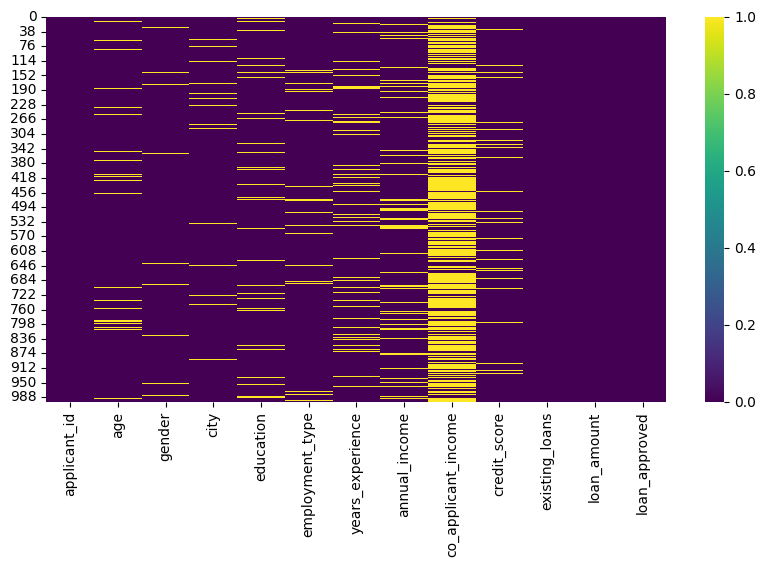

In [19]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(),cmap="viridis")
plt.show()

1. Delete (row,column)
2. Imputation (univariate, multivariate )

Univariate: Mean, Median, mode, constant, ffill, bfill
Multivariate: KNN Imputation, Iterative

In [ ]:
df.shape


(1000, 13)

In [ ]:
df.dropna()

,applicant_id,age,gender,city,education,employment_type,years_experience,annual_income,co_applicant_income,credit_score,existing_loans,loan_amount,loan_approved
1,APP1002,51.0,Male,Hyderabad,Post Graduate,Self-Employed,27.0,1445000.0,550000.0,751.0,0,3060000,0
2,APP1003,47.0,Male,Chandigarh,Post Graduate,Salaried,22.0,493000.0,374000.0,801.0,0,530000,1
7,APP1008,48.0,Female,Bengaluru,Post Graduate,Salaried,25.0,809000.0,167000.0,754.0,1,660000,1
9,APP1010,24.0,Male,Bengaluru,High School,Salaried,0.0,224000.0,239000.0,830.0,0,180000,1
10,APP1011,42.0,Male,Bengaluru,High School,Salaried,19.0,624000.0,164000.0,777.0,1,1840000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978,APP1979,35.0,Male,Pune,Graduate,Salaried,11.0,848000.0,279000.0,616.0,1,1610000,0
982,APP1983,42.0,Male,Mumbai,Graduate,Salaried,18.0,1190000.0,452000.0,731.0,0,1010000,1
989,APP1990,52.0,Female,Delhi,Graduate,Salaried,29.0,779000.0,308000.0,687.0,1,2320000,1
997,APP1998,35.0,Male,Chandigarh,Graduate,Business,10.0,450000.0,573000.0,589.0,1,940000,0


In [26]:
df.dropna(subset=["annual_income","employment_type"])

,applicant_id,age,gender,city,education,employment_type,years_experience,annual_income,co_applicant_income,credit_score,existing_loans,loan_amount,loan_approved
0,APP1001,24.0,Male,Hyderabad,Post Graduate,Self-Employed,0.0,308000.0,NaN,696.0,0,830000,1
1,APP1002,51.0,Male,Hyderabad,Post Graduate,Self-Employed,27.0,1445000.0,550000.0,751.0,0,3060000,0
2,APP1003,47.0,Male,Chandigarh,Post Graduate,Salaried,22.0,493000.0,374000.0,801.0,0,530000,1
3,APP1004,38.0,Male,Bengaluru,Graduate,Salaried,13.0,487000.0,NaN,724.0,0,910000,0
4,APP1005,38.0,Female,Pune,NaN,Salaried,14.0,436000.0,NaN,828.0,0,1040000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,APP1995,42.0,Male,Bengaluru,Graduate,Self-Employed,18.0,1063000.0,NaN,668.0,1,2620000,1
995,APP1996,46.0,Male,Bengaluru,Graduate,Self-Employed,23.0,420000.0,NaN,700.0,3,1090000,0
997,APP1998,35.0,Male,Chandigarh,Graduate,Business,10.0,450000.0,573000.0,589.0,1,940000,0
998,APP1999,59.0,Male,Hyderabad,Graduate,Business,35.0,310000.0,270000.0,685.0,0,930000,0


In [29]:
df.dropna(thresh=12)

,applicant_id,age,gender,city,education,employment_type,years_experience,annual_income,co_applicant_income,credit_score,existing_loans,loan_amount,loan_approved
0,APP1001,24.0,Male,Hyderabad,Post Graduate,Self-Employed,0.0,308000.0,NaN,696.0,0,830000,1
1,APP1002,51.0,Male,Hyderabad,Post Graduate,Self-Employed,27.0,1445000.0,550000.0,751.0,0,3060000,0
2,APP1003,47.0,Male,Chandigarh,Post Graduate,Salaried,22.0,493000.0,374000.0,801.0,0,530000,1
3,APP1004,38.0,Male,Bengaluru,Graduate,Salaried,13.0,487000.0,NaN,724.0,0,910000,0
7,APP1008,48.0,Female,Bengaluru,Post Graduate,Salaried,25.0,809000.0,167000.0,754.0,1,660000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,APP1995,42.0,Male,Bengaluru,Graduate,Self-Employed,18.0,1063000.0,NaN,668.0,1,2620000,1
995,APP1996,46.0,Male,Bengaluru,Graduate,Self-Employed,23.0,420000.0,NaN,700.0,3,1090000,0
997,APP1998,35.0,Male,Chandigarh,Graduate,Business,10.0,450000.0,573000.0,589.0,1,940000,0
998,APP1999,59.0,Male,Hyderabad,Graduate,Business,35.0,310000.0,270000.0,685.0,0,930000,0


In [34]:
cols_to_drop = missing[missing["missing_pct"]>50].index.tolist()

In [36]:
df.drop(columns=cols_to_drop).columns

Index(['applicant_id', 'age', 'gender', 'city', 'education', 'employment_type',
       'years_experience', 'annual_income', 'credit_score', 'existing_loans',
       'loan_amount', 'loan_approved'],
      dtype='str')

## Imputation

In [37]:
df5 = df.copy()

708882.69

In [41]:
# mean fill
df5['income_mean'] = df5['annual_income'].fillna(df5['annual_income'].mean().round(2))

In [44]:
# median fill
df5['income_median'] = df5['annual_income'].fillna(df5['annual_income'].median().round(2))


In [45]:
df5.head(20)

,applicant_id,age,gender,city,education,employment_type,years_experience,annual_income,co_applicant_income,credit_score,existing_loans,loan_amount,loan_approved,income_mean,income_median
0,APP1001,24.0,Male,Hyderabad,Post Graduate,Self-Employed,0.0,308000.0,NaN,696.0,0,830000,1,308000.00,308000.0
1,APP1002,51.0,Male,Hyderabad,Post Graduate,Self-Employed,27.0,1445000.0,550000.0,751.0,0,3060000,0,1445000.00,1445000.0
2,APP1003,47.0,Male,Chandigarh,Post Graduate,Salaried,22.0,493000.0,374000.0,801.0,0,530000,1,493000.00,493000.0
3,APP1004,38.0,Male,Bengaluru,Graduate,Salaried,13.0,487000.0,NaN,724.0,0,910000,0,487000.00,487000.0
4,APP1005,38.0,Female,Pune,NaN,Salaried,14.0,436000.0,NaN,828.0,0,1040000,1,436000.00,436000.0
5,APP1006,55.0,Female,Bengaluru,Post Graduate,Salaried,32.0,NaN,NaN,758.0,0,3340000,0,708882.69,609500.0
6,APP1007,24.0,Male,Hyderabad,Graduate,Salaried,NaN,300000.0,NaN,685.0,2,270000,1,300000.00,300000.0
7,APP1008,48.0,Female,Bengaluru,Post Graduate,Salaried,25.0,809000.0,167000.0,754.0,1,660000,1,809000.00,809000.0
8,APP1009,29.0,Male,Mumbai,Graduate,Business,5.0,408000.0,NaN,811.0,3,630000,1,408000.00,408000.0
9,APP1010,24.0,Male,Bengaluru,High School,Salaried,0.0,224000.0,239000.0,830.0,0,180000,1,224000.00,224000.0


In [53]:
print(df5['annual_income'].std())
print(df5['income_mean'].std())

429477.9904266968
402399.99337913515


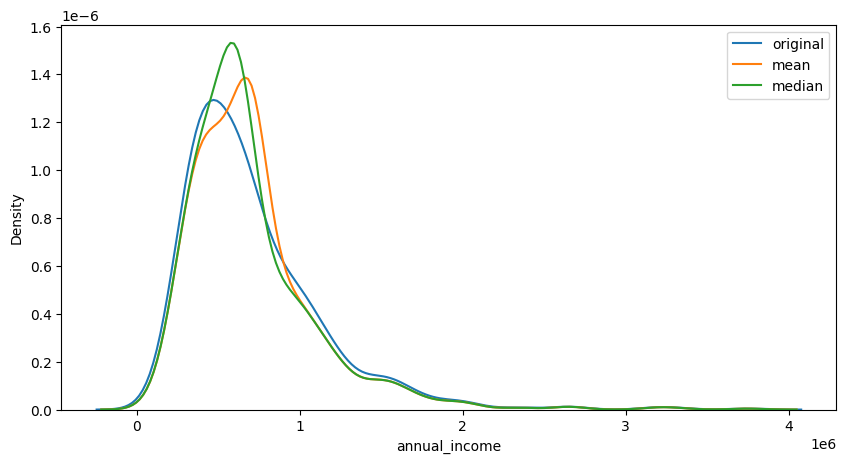

In [49]:
fig,ax = plt.subplots(figsize=(10,5))

sns.kdeplot(df5['annual_income'].dropna(),label="original",ax=ax)
sns.kdeplot(df5['income_mean'],label="mean",ax=ax)
sns.kdeplot(df5['income_median'],label="median",ax=ax)
plt.legend()
plt.show()



In [54]:
temp = pd.read_csv("city_daily_temperature.csv")

In [58]:
temp['temperature_c'].isnull().sum()

12

In [55]:
temp['ffill'] = temp['temperature_c'].ffill()

In [59]:
temp['bfill'] = temp['temperature_c'].bfill()


In [62]:
temp.iloc[28:50]

,date,city,temperature_c,ffill,bfill
28,2026-01-29,Chandigarh,9.0,9.0,9.0
29,2026-01-30,Chandigarh,7.6,7.6,7.6
30,2026-01-31,Chandigarh,NaN,7.6,10.9
31,2026-02-01,Chandigarh,NaN,7.6,10.9
32,2026-02-02,Chandigarh,NaN,7.6,10.9
33,2026-02-03,Chandigarh,10.9,10.9,10.9
34,2026-02-04,Chandigarh,14.7,14.7,14.7
35,2026-02-05,Chandigarh,NaN,14.7,13.0
36,2026-02-06,Chandigarh,13.0,13.0,13.0
37,2026-02-07,Chandigarh,14.6,14.6,14.6


In [ ]:
df5['employment_type_fill'] = df5['employment_type'].fillna("Unknown")


In [66]:
df5['employment_type_fill_mode'] = df5['employment_type'].fillna(df5['employment_type'].mode()[0])


In [67]:
df5[['employment_type','employment_type_fill','employment_type_fill_mode']].head(20)

,employment_type,employment_type_fill,employment_type_fill_mode
0,Self-Employed,Self-Employed,Self-Employed
1,Self-Employed,Self-Employed,Self-Employed
2,Salaried,Salaried,Salaried
3,Salaried,Salaried,Salaried
4,Salaried,Salaried,Salaried
5,Salaried,Salaried,Salaried
6,Salaried,Salaried,Salaried
7,Salaried,Salaried,Salaried
8,Business,Business,Business
9,Salaried,Salaried,Salaried


In [ ]:
pip install scikit-learn

scikit learn

In [71]:
from sklearn.impute import SimpleImputer

In [73]:
df6 = df.drop(columns=['co_applicant_income']) 

In [74]:
df6.head()

,applicant_id,age,gender,city,education,employment_type,years_experience,annual_income,credit_score,existing_loans,loan_amount,loan_approved
0,APP1001,24.0,Male,Hyderabad,Post Graduate,Self-Employed,0.0,308000.0,696.0,0,830000,1
1,APP1002,51.0,Male,Hyderabad,Post Graduate,Self-Employed,27.0,1445000.0,751.0,0,3060000,0
2,APP1003,47.0,Male,Chandigarh,Post Graduate,Salaried,22.0,493000.0,801.0,0,530000,1
3,APP1004,38.0,Male,Bengaluru,Graduate,Salaried,13.0,487000.0,724.0,0,910000,0
4,APP1005,38.0,Female,Pune,NaN,Salaried,14.0,436000.0,828.0,0,1040000,1


In [84]:
num_cols = ["age","years_experience","annual_income","credit_score"]
cat_cols = ["gender","city","education","employment_type"]

num_imputer = SimpleImputer(strategy="median")

num_imputer.fit(df6[num_cols])

print(num_imputer.statistics_)

pd.DataFrame(num_imputer.transform(df6[num_cols]),columns=df6[num_cols].columns)

[4.100e+01 1.850e+01 6.095e+05 6.980e+02]


,age,years_experience,annual_income,credit_score
0,24.0,0.0,308000.0,696.0
1,51.0,27.0,1445000.0,751.0
2,47.0,22.0,493000.0,801.0
3,38.0,13.0,487000.0,724.0
4,38.0,14.0,436000.0,828.0
...,...,...,...,...
995,46.0,23.0,420000.0,700.0
996,42.0,20.0,1132000.0,708.0
997,35.0,10.0,450000.0,589.0
998,59.0,35.0,310000.0,685.0


In [86]:
df6

,applicant_id,age,gender,city,education,employment_type,years_experience,annual_income,credit_score,existing_loans,loan_amount,loan_approved
0,APP1001,24.0,Male,Hyderabad,Post Graduate,Self-Employed,0.0,308000.0,696.0,0,830000,1
1,APP1002,51.0,Male,Hyderabad,Post Graduate,Self-Employed,27.0,1445000.0,751.0,0,3060000,0
2,APP1003,47.0,Male,Chandigarh,Post Graduate,Salaried,22.0,493000.0,801.0,0,530000,1
3,APP1004,38.0,Male,Bengaluru,Graduate,Salaried,13.0,487000.0,724.0,0,910000,0
4,APP1005,38.0,Female,Pune,NaN,Salaried,14.0,436000.0,828.0,0,1040000,1
...,...,...,...,...,...,...,...,...,...,...,...,...
995,APP1996,46.0,Male,Bengaluru,Graduate,Self-Employed,23.0,420000.0,700.0,3,1090000,0
996,APP1997,42.0,Female,Mumbai,Post Graduate,NaN,20.0,1132000.0,708.0,1,3190000,1
997,APP1998,35.0,Male,Chandigarh,Graduate,Business,10.0,450000.0,589.0,1,940000,0
998,APP1999,59.0,Male,Hyderabad,Graduate,Business,35.0,310000.0,685.0,0,930000,0


In [90]:
cat_imputer = SimpleImputer(strategy="most_frequent")

pd.DataFrame(cat_imputer.fit_transform(df6[cat_cols]),columns=df[cat_cols].columns)

,gender,city,education,employment_type
0,Male,Hyderabad,Post Graduate,Self-Employed
1,Male,Hyderabad,Post Graduate,Self-Employed
2,Male,Chandigarh,Post Graduate,Salaried
3,Male,Bengaluru,Graduate,Salaried
4,Female,Pune,Graduate,Salaried
...,...,...,...,...
995,Male,Bengaluru,Graduate,Self-Employed
996,Female,Mumbai,Post Graduate,Salaried
997,Male,Chandigarh,Graduate,Business
998,Male,Hyderabad,Graduate,Business


In [ ]:
SimpleImputer(strategy="constant",fill_value="missing").fit_transform(df6[['education']])

array([['Post Graduate'],
       ['Post Graduate'],
       ['Post Graduate'],
       ['Graduate'],
       ['missing'],
       ['Post Graduate'],
       ['Graduate'],
       ['Post Graduate'],
       ['Graduate'],
       ['High School'],
       ['High School'],
       ['Post Graduate'],
       ['missing'],
       ['Graduate'],
       ['Graduate'],
       ['High School'],
       ['Graduate'],
       ['Post Graduate'],
       ['High School'],
       ['Post Graduate'],
       ['Post Graduate'],
       ['Graduate'],
       ['High School'],
       ['Graduate'],
       ['High School'],
       ['Graduate'],
       ['PhD'],
       ['PhD'],
       ['Post Graduate'],
       ['Graduate'],
       ['Post Graduate'],
       ['Post Graduate'],
       ['Graduate'],
       ['Graduate'],
       ['High School'],
       ['missing'],
       ['Graduate'],
       ['High School'],
       ['High School'],
       ['Post Graduate'],
       ['PhD'],
       ['Graduate'],
       ['Post Graduate'],
       ['PhD'],
  

In [95]:
SimpleImputer(strategy="mean").set_output(transform='pandas').fit_transform(df6[num_cols])


,age,years_experience,annual_income,credit_score
0,24.0,0.0,308000.0,696.0
1,51.0,27.0,1445000.0,751.0
2,47.0,22.0,493000.0,801.0
3,38.0,13.0,487000.0,724.0
4,38.0,14.0,436000.0,828.0
...,...,...,...,...
995,46.0,23.0,420000.0,700.0
996,42.0,20.0,1132000.0,708.0
997,35.0,10.0,450000.0,589.0
998,59.0,35.0,310000.0,685.0


### Missing Indicator

In [97]:
df7 = df6.copy()

In [104]:
df7.head(20)

,applicant_id,age,gender,city,education,employment_type,years_experience,annual_income,credit_score,existing_loans,loan_amount,loan_approved,income_was_missing
0,APP1001,24.0,Male,Hyderabad,Post Graduate,Self-Employed,0.0,308000.0,696.0,0,830000,1,0
1,APP1002,51.0,Male,Hyderabad,Post Graduate,Self-Employed,27.0,1445000.0,751.0,0,3060000,0,0
2,APP1003,47.0,Male,Chandigarh,Post Graduate,Salaried,22.0,493000.0,801.0,0,530000,1,0
3,APP1004,38.0,Male,Bengaluru,Graduate,Salaried,13.0,487000.0,724.0,0,910000,0,0
4,APP1005,38.0,Female,Pune,NaN,Salaried,14.0,436000.0,828.0,0,1040000,1,0
5,APP1006,55.0,Female,Bengaluru,Post Graduate,Salaried,32.0,NaN,758.0,0,3340000,0,1
6,APP1007,24.0,Male,Hyderabad,Graduate,Salaried,NaN,300000.0,685.0,2,270000,1,0
7,APP1008,48.0,Female,Bengaluru,Post Graduate,Salaried,25.0,809000.0,754.0,1,660000,1,0
8,APP1009,29.0,Male,Mumbai,Graduate,Business,5.0,408000.0,811.0,3,630000,1,0
9,APP1010,24.0,Male,Bengaluru,High School,Salaried,0.0,224000.0,830.0,0,180000,1,0


In [103]:
df7['income_was_missing'] = df7['annual_income'].isnull().astype(int)

In [105]:
df7.groupby('income_was_missing')['loan_amount'].mean().round(2)

income_was_missing
0    1237779.04
1    1978196.72
Name: loan_amount, dtype: float64

In [107]:
imp_ind = SimpleImputer(strategy="median",add_indicator=True).set_output(transform='pandas')

In [112]:
out = imp_ind.fit_transform(df7[['annual_income','years_experience']]).head(20)

In [113]:
out.columns.tolist()

['annual_income',
 'years_experience',
 'missingindicator_annual_income',
 'missingindicator_years_experience']

## KNN Imputer

In [115]:
from sklearn.impute import KNNImputer

In [116]:
knn_cols = ['age','years_experience','annual_income','credit_score',"loan_amount",'existing_loans']



# Without Scaling

In [117]:
df8 = df6.copy()

In [121]:
df8[knn_cols].isnull().sum()

age                  44
years_experience    106
annual_income       122
credit_score         73
loan_amount           0
existing_loans        0
dtype: int64

In [118]:
knn_imputer = KNNImputer(n_neighbors=5).set_output(transform='pandas')

df_knn_raw = knn_imputer.fit_transform(df8[knn_cols])

In [120]:
df_knn_raw.isnull().sum()

age                 0
years_experience    0
annual_income       0
credit_score        0
loan_amount         0
existing_loans      0
dtype: int64

In [122]:
from sklearn.preprocessing import StandardScaler

In [124]:
scaler= StandardScaler().set_output(transform='pandas')

In [126]:
scaled = scaler.fit_transform(df8[knn_cols])

In [128]:
df8[knn_cols]

,age,years_experience,annual_income,credit_score,loan_amount,existing_loans
0,24.0,0.0,308000.0,696.0,830000,0
1,51.0,27.0,1445000.0,751.0,3060000,0
2,47.0,22.0,493000.0,801.0,530000,0
3,38.0,13.0,487000.0,724.0,910000,0
4,38.0,14.0,436000.0,828.0,1040000,0
...,...,...,...,...,...,...
995,46.0,23.0,420000.0,700.0,1090000,3
996,42.0,20.0,1132000.0,708.0,3190000,1
997,35.0,10.0,450000.0,589.0,940000,1
998,59.0,35.0,310000.0,685.0,930000,0


In [134]:
scaled

,age,years_experience,annual_income,credit_score,loan_amount,existing_loans
0,-1.454857,-1.683747,-0.933950,-0.086604,-0.479950,-0.913447
1,0.886776,0.782411,1.714958,0.727914,1.668750,-0.913447
2,0.539867,0.325715,-0.502949,1.468384,-0.769013,-0.913447
3,-0.240677,-0.496338,-0.516928,0.328060,-0.402867,-0.913447
4,-0.240677,-0.404998,-0.635744,1.868238,-0.277606,-0.913447
...,...,...,...,...,...,...
995,0.453140,0.417054,-0.673020,-0.027366,-0.229429,2.272997
996,0.106232,0.143037,0.985751,0.091109,1.794010,0.148701
997,-0.500858,-0.770355,-0.603128,-1.671211,-0.373961,0.148701
998,1.580593,1.513125,-0.929291,-0.249507,-0.383596,-0.913447


In [130]:
knn_scaled = KNNImputer(n_neighbors=5).set_output(transform='pandas').fit_transform(scaled)

In [138]:
df_knn = pd.DataFrame(scaler.inverse_transform(knn_scaled),columns=knn_cols)

In [142]:
print(df6['years_experience'].median())

18.5


In [146]:
df_knn_raw.loc[6,'age']


24.0

In [143]:
df_knn_raw.loc[6,'years_experience']

12.2

In [144]:
df_knn.loc[6,'years_experience']

1.7999999999999972